# A Color Histogram Baseline for Fruit and Vegetable Classification

**Project question.** How well can a simple model recognize nine kinds of food using color alone?

EDA identified 2,003 photos across nine target classes. Apple varieties share the label `apple`, and potato varieties share `potato`. Many photos have large areas of background. That gives us our first experiment: does skipping background-colored pixels help the model recognize the food?

**Presentation path**

1. Start with the shared split and turn each photo into 96 color features.
2. Compare three ways of counting pixels and explain why we chose Mask 80.
3. Try PCA and cropping before resizing as follow-up experiments on validation.
4. Close with the selected baseline's test result and the files the group can reuse.

A **baseline** is the reference model the group compares against. Here it is logistic regression using color histograms. Run from top to bottom to reproduce the tables and figures, or use the saved outputs for the presentation.

## 1. Use the Shared Split

`data/dataset_split.csv` gives us the image path, the correct food label, and the split. The image paths are relative to the project root.

| Split | Photos | Role |
|---|---:|---|
| Training | 1,603 | Fit the model |
| Validation | 200 | Compare preprocessing choices |
| Test | 200 | Report the selected baseline's final score |

Think of training as practice, validation as a trial exam, and test as the final exam. Using the same photos in each split makes the group's scores comparable.

In [1]:
import sys
from pathlib import Path

import numpy as np
from PIL import Image
from IPython.display import display

project_folder = Path.cwd()
if project_folder.name == "notebooks":
    project_folder = project_folder.parent

if str(project_folder) not in sys.path:
    sys.path.insert(0, str(project_folder))

In [2]:
import pandas as pd

split_path = project_folder / "data" / "dataset_split.csv"
split_table = pd.read_csv(split_path)

experiment_rows = split_table[split_table["split"].isin(["train", "validation"])]
is_training = experiment_rows["split"].eq("train").to_numpy()
labels = experiment_rows["target_class"].to_numpy()

print("Training photos:", is_training.sum())
print("Validation photos:", (~is_training).sum())
display(experiment_rows.head(3))

Training photos: 1603
Validation photos: 200


,image_path,target_class,split
200,data/raw_images/fuji_apple/fuji_apple_001.jpg,apple,train
201,data/raw_images/fuji_apple/fuji_apple_003.jpg,apple,train
202,data/raw_images/fuji_apple/fuji_apple_004.jpg,apple,train


## 2. Turn Each Photo into 96 Color Features

### 2.1 Count Color Intensities

An RGB pixel has three values, one each for red, green, and blue. A histogram sorts pixel values into buckets. For example, the first red bucket counts red values from 0 to 7 and the second counts values from 8 to 15. We divide each count by its total to get the share of pixels in that bucket.

```text
1 photo → 32 red shares + 32 green shares + 32 blue shares → 96 features
```

Each photo becomes one row, with its correct food label alongside it. The histogram keeps the color distribution and loses pixel positions. An apple on the left can have a similar histogram to an apple on the right.

### 2.2 Decide Which Pixels to Count

Following the EDA method, we estimate the background color from four patches at the corners of the original photo. **Color distance** measures how different a pixel is from that estimated background, using its RGB values.

| Version | Pixels counted |
|---|---|
| Whole image | Every pixel |
| Mask 65 | Pixels more than 65 color-distance units from the background |
| Mask 80 | Pixels more than 80 color-distance units from the background |

A pixel at distance **70** is counted by Mask 65 and skipped by Mask 80. The higher cutoff skips a wider range of colors, which can include food pixels. When a mask skips every pixel, we count the whole photo so it stays in the comparison.

In [3]:
def rgb_histogram_features(pixels):
    channel_histograms = []

    for channel in range(3):
        counts, _ = np.histogram(pixels[:, channel], bins=32, range=(0, 256))
        channel_histograms.append(counts / counts.sum())

    return np.concatenate(channel_histograms)


def background_color_distance(image):
    height, width, _ = image.shape
    corner_height = max(1, int(height * 0.10))
    corner_width = max(1, int(width * 0.10))

    corners = [
        image[:corner_height, :corner_width],
        image[:corner_height, -corner_width:],
        image[-corner_height:, :corner_width],
        image[-corner_height:, -corner_width:]
    ]
    corner_pixels = np.concatenate([corner.reshape(-1, 3) for corner in corners])
    background_color = np.median(corner_pixels, axis=0).astype(np.uint8)

    pixels = image.reshape(-1, 3).astype(np.float32)
    difference = pixels - background_color.astype(np.float32)
    return np.linalg.norm(difference, axis=1)

In [4]:
thresholds = {"Whole image": None, "Mask 65": 65, "Mask 80": 80}
feature_rows = {name: [] for name in thresholds}
empty_mask_counts = {name: 0 for name in thresholds if thresholds[name] is not None}

for image_path in experiment_rows["image_path"]:
    with Image.open(project_folder / image_path) as source:
        image = np.array(source.convert("RGB"))

    pixels = image.reshape(-1, 3)
    whole_image_features = rgb_histogram_features(pixels)
    color_distance = background_color_distance(image)

    for name, threshold in thresholds.items():
        features = whole_image_features
        if threshold is not None:
            selected_pixels = pixels[color_distance > threshold]
            if len(selected_pixels) > 0:
                features = rgb_histogram_features(selected_pixels)
            else:
                empty_mask_counts[name] += 1

        feature_rows[name].append(features)

feature_tables = {name: np.array(rows) for name, rows in feature_rows.items()}
for name, X in feature_tables.items():
    print(name, "- training shape", X[is_training].shape,
          "- validation shape", X[~is_training].shape)

print("Empty masks that used the whole image:", empty_mask_counts)

Whole image - training shape (1603, 96) - validation shape (200, 96)
Mask 65 - training shape (1603, 96) - validation shape (200, 96)
Mask 80 - training shape (1603, 96) - validation shape (200, 96)
Empty masks that used the whole image: {'Mask 65': 9, 'Mask 80': 17}


## 3. Choose the Baseline on Validation

### 3.1 Compare the Three Versions

#### Learning note – From two answers to nine

**Binary logistic regression** is like a quiz with two buttons. It could answer “apple” or “not apple.” A kiwi and a potato would both go under “not apple.” Our quiz has nine buttons, one for each food class, and each photo has one correct answer. Scikit-learn's `LogisticRegression` uses **multinomial logistic regression** for this setup.

1. **Read the photo's 96 color features.** They tell the model how common different color intensities are in the photo.
2. **Give each food a score.** During training, the model learns which color features raise or lower each food's score. It uses those weights to calculate nine scores for a new photo.
3. **Turn the scores into probabilities and pick the largest.** This conversion is called **softmax**. The nine probabilities add up to 100%.

Here is a made-up result for one photo:

| Food | Example probability |
|---|---:|
| Apple | **62%** |
| Nectarine | 18% |
| Kiwi | 10% |
| Plum | 3% |
| Potato | 2% |
| Spanish pear | 2% |
| Onion | 1% |
| Honeydew melon | 1% |
| Watermelon | 1% |

The model predicts **apple** because apple has the highest score and therefore the highest probability. When we check the prediction against the photo's actual label, we can count it as a correct guess or a mistake.

The three versions below use the same model settings and split.

**Accuracy** is the share of photos classified correctly. **Macro-F1** gives each food its own score, then averages the scores equally. Each food's F1 balances how many of its photos we find and how often guesses of that food are right. We use macro-F1 to choose a version because some foods have fewer photos.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

validation_results = []
validation_predictions = {}
for name, X in feature_tables.items():
    X_train = X[is_training]
    y_train = labels[is_training]
    X_validation = X[~is_training]
    y_validation = labels[~is_training]

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)
    predictions = model.predict(X_validation)
    validation_predictions[name] = predictions

    validation_results.append({
        "Image preparation": name,
        "Accuracy": accuracy_score(y_validation, predictions),
        "Macro-F1": f1_score(y_validation, predictions, average="macro", zero_division=0)
    })

validation_scores = pd.DataFrame(validation_results)
display(validation_scores.round(4))

,Image preparation,Accuracy,Macro-F1
0,Whole image,0.715,0.5795
1,Mask 65,0.730,0.6401
2,Mask 80,0.720,0.6648


### 3.2 See Which Foods the Masks Confuse

A confusion matrix is a tally sheet. Pick the actual food on the left and read across to see the guesses. An onion guessed as potato adds one tally to the onion row and potato column. The diagonal shows correct guesses. The two charts share the same class order and color scale.

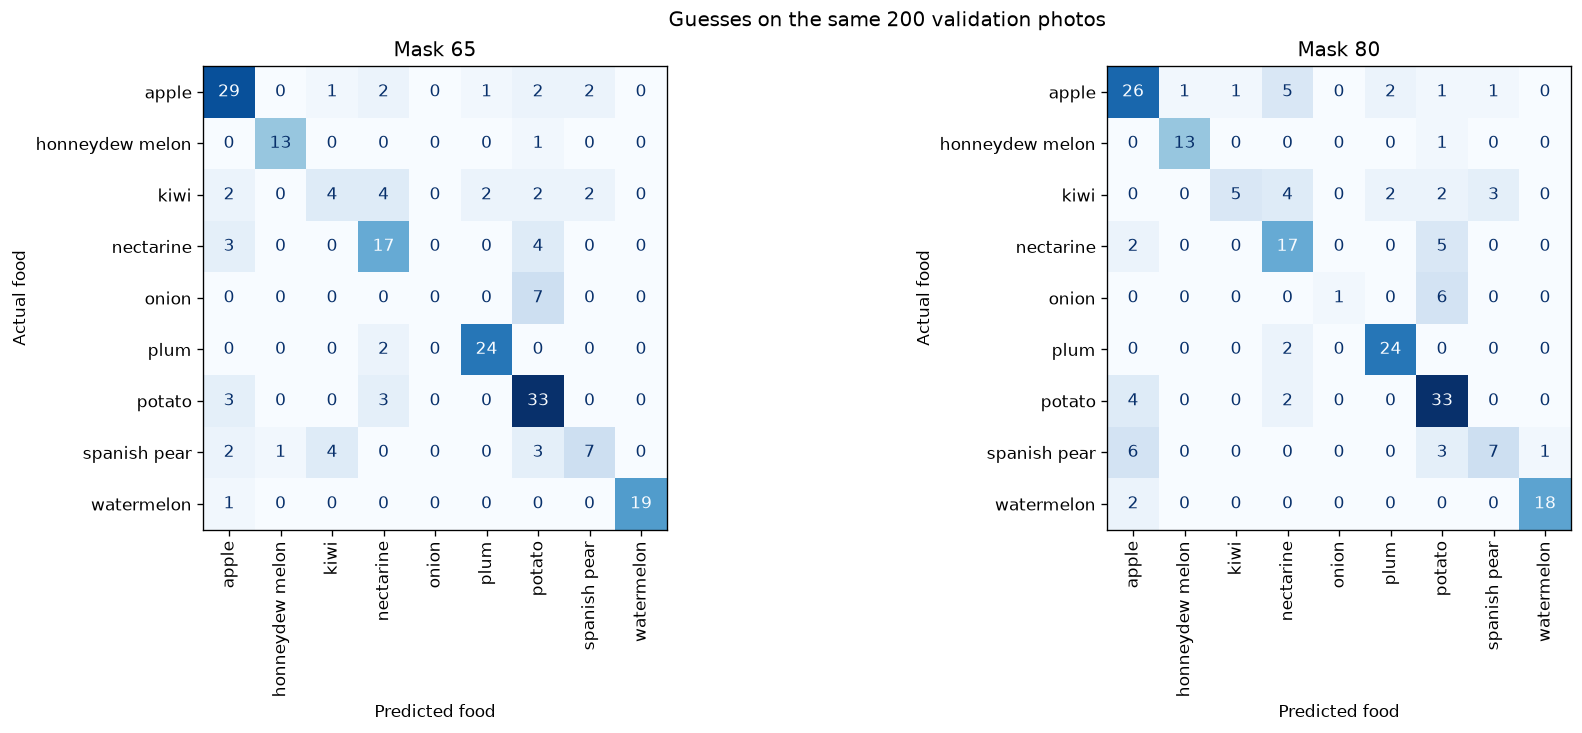

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

mask_names = ["Mask 65", "Mask 80"]
class_names = sorted(set(y_validation))
display_names = [name.replace("_", " ") for name in class_names]
confusion_counts = {}

for name in mask_names:
    confusion_counts[name] = confusion_matrix(
        y_validation, validation_predictions[name], labels=class_names
    )

max_count = max(matrix.max() for matrix in confusion_counts.values())
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")

for name, ax in zip(mask_names, axes):
    matrix_plot = ConfusionMatrixDisplay(
        confusion_counts[name], display_labels=display_names
    )
    matrix_plot.plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=90)
    matrix_plot.im_.set_clim(0, max_count)
    ax.set_title(name)
    ax.set_xlabel("Predicted food")
    ax.set_ylabel("Actual food")

fig.suptitle("Guesses on the same 200 validation photos")
plt.show()
plt.close(fig)

The table shows each food's F1 and how many validation photos it had. The last column gives the change from Mask 65 to Mask 80.

In [7]:
per_class_scores = pd.DataFrame({
    "Food": display_names,
    "Validation photos": confusion_counts["Mask 65"].sum(axis=1)
})

for name in mask_names:
    per_class_scores[f"F1 {name}"] = f1_score(
        y_validation,
        validation_predictions[name],
        labels=class_names,
        average=None,
        zero_division=0
    )

per_class_scores["F1 change (80 minus 65)"] = (
    per_class_scores["F1 Mask 80"] - per_class_scores["F1 Mask 65"]
)
display(per_class_scores.round(3))

,Food,Validation photos,F1 Mask 65,F1 Mask 80,F1 change (80 minus 65)
0,apple,37,0.753,0.675,-0.078
1,honneydew melon,14,0.929,0.929,0.000
2,kiwi,16,0.320,0.455,0.135
3,nectarine,24,0.654,0.630,-0.024
4,onion,7,0.000,0.250,0.250
5,plum,26,0.906,0.889,-0.017
6,potato,39,0.725,0.733,0.008
7,spanish pear,17,0.500,0.500,0.000
8,watermelon,20,0.974,0.923,-0.051


#### Decision – Mask 80

Mask 65 got **146 of 200** photos right. Mask 80 got **144** right and had the higher macro-F1, **0.665 versus 0.640**. Its biggest F1 gains were on onion and kiwi. Mask 80 correctly identified one of the seven onion photos, which raised onion's F1 from 0 to 0.250. Apple F1 fell from 0.753 to 0.675.

We selected **Mask 80 with all 96 features** using validation macro-F1. The next two sections are follow-up experiments on validation. The final test result belongs to the selected baseline.

## 4. Follow-up Experiment – Can PCA Shorten the Color Description?

PCA combines the 96 color columns into fewer columns called **principal components**. Imagine several color buckets that tend to rise and fall together. One combined number can capture much of that shared pattern. Each row still represents the same photo.

We fit PCA on training features and keep enough components to explain at least 95% of their variation. Then we apply those same combinations to validation features. The table shows what happened to the rows and columns.

In [8]:
from sklearn.decomposition import PCA

mask_80_features = feature_tables["Mask 80"]
X_train_mask_80 = mask_80_features[is_training]
X_validation_mask_80 = mask_80_features[~is_training]
y_train_mask_80 = labels[is_training]
y_validation_mask_80 = labels[~is_training]

pca = PCA(n_components=0.95, svd_solver="full")
X_train_pca = pca.fit_transform(X_train_mask_80)
X_validation_pca = pca.transform(X_validation_mask_80)

shape_comparison = pd.DataFrame([
    {
        "Split": "Training",
        "Photos": X_train_mask_80.shape[0],
        "Columns before PCA": X_train_mask_80.shape[1],
        "Columns after PCA": X_train_pca.shape[1]
    },
    {
        "Split": "Validation",
        "Photos": X_validation_mask_80.shape[0],
        "Columns before PCA": X_validation_mask_80.shape[1],
        "Columns after PCA": X_validation_pca.shape[1]
    }
])
display(shape_comparison)
print(f"Training variation explained: {pca.explained_variance_ratio_.sum():.1%}")

Training variation explained: 95.2%


,Split,Photos,Columns before PCA,Columns after PCA
0,Training,1603,96,33
1,Validation,200,96,33


We fit logistic regression with the same settings on the shorter description and compare it with the original Mask 80 validation result.

In [9]:
from sklearn.linear_model import LogisticRegression
from src.evaluate import evaluate_predictions

pca_model = LogisticRegression(max_iter=1000)
pca_model.fit(X_train_pca, y_train_mask_80)
pca_validation_predictions = pca_model.predict(X_validation_pca)

pca_class_names = sorted(split_table["target_class"].unique())
pca_validation_scores = evaluate_predictions(
    y_validation_mask_80, pca_validation_predictions, pca_class_names
)

mask_80_score = validation_scores.loc[
    validation_scores["Image preparation"].eq("Mask 80")
].iloc[0]

pca_comparison = pd.DataFrame([
    {
        "Version": "Mask 80",
        "Features per photo": X_train_mask_80.shape[1],
        "Validation accuracy": mask_80_score["Accuracy"],
        "Validation macro-F1": mask_80_score["Macro-F1"]
    },
    {
        "Version": "Mask 80 + PCA",
        "Features per photo": X_train_pca.shape[1],
        "Validation accuracy": pca_validation_scores["accuracy"],
        "Validation macro-F1": pca_validation_scores["macro_f1"]
    }
])
display(pca_comparison.round(4))

,Version,Features per photo,Validation accuracy,Validation macro-F1
0,Mask 80,96,0.72,0.6648
1,Mask 80 + PCA,33,0.69,0.6360


**Result.** PCA kept **33 of 96 columns**, explaining **95.2%** of the training feature variation. Validation accuracy fell from **72.0% to 69.0%** and macro-F1 fell from **0.665 to 0.636**. We kept all 96 features for the baseline.

## 5. Follow-up Experiment – Does Cropping Before Resizing Help?

A crop keeps a rectangle from the photo. We estimate the background from the original corners, find pixels that differ from it, and draw a box around those pixels with a 32-pixel margin. A background speck can make the box too wide, and food close to the background color can be missed.

We compare **whole photo → resize** with **crop → resize**. Both versions fit within **64 × 48 pixels** and keep their proportions. The histogram counts all pixels in the resized result, which gives 96 features even when one crop is narrower than another. The previews show training photos.

In [10]:
background_threshold = 50
corner_size = 40
crop_margin = 32

def estimate_crop_box(image, threshold, corner_size, margin):
    pixels = np.asarray(image, dtype="float32")

    top_left = pixels[:corner_size, :corner_size]
    top_right = pixels[:corner_size, -corner_size:]
    bottom_left = pixels[-corner_size:, :corner_size]
    bottom_right = pixels[-corner_size:, -corner_size:]

    corner_pixels = np.concatenate([
        top_left.reshape(-1, 3),
        top_right.reshape(-1, 3),
        bottom_left.reshape(-1, 3),
        bottom_right.reshape(-1, 3)
    ])
    background_color = np.median(corner_pixels, axis=0)

    color_difference = np.abs(pixels - background_color)
    largest_difference = color_difference.max(axis=2)
    foreground_mask = largest_difference > threshold

    row_positions, column_positions = np.where(foreground_mask)

    if len(column_positions) == 0:
        crop_box = (0, 0, image.width, image.height)
    else:
        left = max(0, int(column_positions.min()) - margin)
        top = max(0, int(row_positions.min()) - margin)
        right = min(image.width, int(column_positions.max()) + 1 + margin)
        bottom = min(image.height, int(row_positions.max()) + 1 + margin)
        crop_box = (left, top, right, bottom)

    return crop_box, foreground_mask, background_color

data/raw_images/fuji_apple/fuji_apple_001.jpg
data/raw_images/kiwi/kiwi_001.jpg
data/raw_images/plum/plum_002.jpg


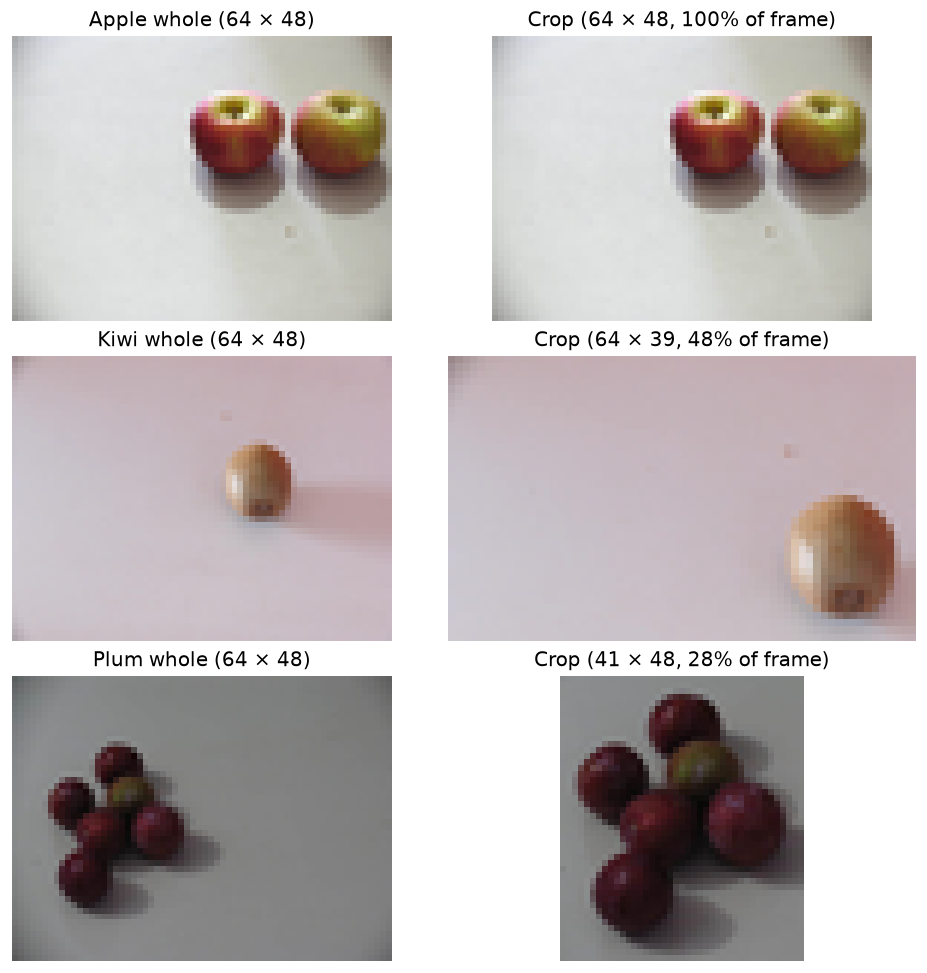

In [11]:
from PIL import ImageOps
import matplotlib.pyplot as plt

crop_resize_limit = (64, 48)


def resize_for_crop_experiment(photo):
    return ImageOps.contain(photo, crop_resize_limit, Image.Resampling.LANCZOS)


def crop_for_experiment(photo):
    box, _, _ = estimate_crop_box(
        photo, threshold=background_threshold, corner_size=corner_size, margin=crop_margin
    )
    return photo.crop(box), box


training_examples = experiment_rows[experiment_rows["split"].eq("train")]
fig, axes = plt.subplots(3, 2, figsize=(8, 8), layout="constrained")
for row, food in enumerate(["apple", "kiwi", "plum"]):
    crop_preview_path = training_examples.loc[
        training_examples["target_class"].eq(food), "image_path"
    ].iloc[0]
    with Image.open(project_folder / crop_preview_path) as source:
        original_photo = source.convert("RGB")

    crop_preview, _ = crop_for_experiment(original_photo)
    whole_small = resize_for_crop_experiment(original_photo)
    crop_small = resize_for_crop_experiment(crop_preview)
    crop_share = (crop_preview.width * crop_preview.height) / (original_photo.width * original_photo.height)
    for ax, preview in zip(axes[row], [whole_small, crop_small]):
        ax.imshow(preview, interpolation="nearest")
        ax.axis("off")
    axes[row, 0].set_title(f"{food.title()} whole ({whole_small.width} × {whole_small.height})")
    axes[row, 1].set_title(f"Crop ({crop_small.width} × {crop_small.height}, {crop_share:.0%} of frame)")
    print(crop_preview_path)

plt.show()
plt.close(fig)

Both versions use the same training and validation photos. A crop that keeps the full frame gives identical features to the resized whole photo. Compare the first two rows of the score table to see what adding the crop changed. Mask 80 serves as a reference and used original-resolution pixels.

In [12]:
whole_resize_rows = []
crop_resize_rows = []
full_frame_crops = []

for image_path in experiment_rows["image_path"]:
    with Image.open(project_folder / image_path) as source:
        photo = source.convert("RGB")

    cropped_photo, box = crop_for_experiment(photo)
    full_frame_crops.append(box == (0, 0, photo.width, photo.height))
    whole_pixels = np.asarray(resize_for_crop_experiment(photo)).reshape(-1, 3)
    crop_pixels = np.asarray(resize_for_crop_experiment(cropped_photo)).reshape(-1, 3)
    whole_resize_rows.append(rgb_histogram_features(whole_pixels))
    crop_resize_rows.append(rgb_histogram_features(crop_pixels))

resize_feature_tables = {
    "Whole image → resize": np.array(whole_resize_rows),
    "Crop → resize": np.array(crop_resize_rows)
}
full_frame_crops = np.array(full_frame_crops)
print("Feature table shape for each version:", resize_feature_tables["Crop → resize"].shape)
print("Full-frame crops in training:", full_frame_crops[is_training].sum(), "of", is_training.sum())
print("Full-frame crops in validation:", full_frame_crops[~is_training].sum(), "of", (~is_training).sum())

Feature table shape for each version: (1803, 96)
Full-frame crops in training: 518 of 1603
Full-frame crops in validation: 71 of 200


In [13]:
from sklearn.linear_model import LogisticRegression
from src.evaluate import evaluate_predictions

resize_class_names = sorted(split_table["target_class"].unique())
resize_results = []
for name, features in resize_feature_tables.items():
    resize_model = LogisticRegression(max_iter=1000)
    resize_model.fit(features[is_training], labels[is_training])
    resize_predictions = resize_model.predict(features[~is_training])
    resize_scores = evaluate_predictions(labels[~is_training], resize_predictions, resize_class_names)
    resize_results.append({
        "Image preparation": name,
        "Validation accuracy": resize_scores["accuracy"],
        "Validation macro-F1": resize_scores["macro_f1"]
    })

mask_reference = validation_scores.loc[validation_scores["Image preparation"].eq("Mask 80")].iloc[0]
resize_results.append({
    "Image preparation": "Mask 80 (reference)",
    "Validation accuracy": mask_reference["Accuracy"],
    "Validation macro-F1": mask_reference["Macro-F1"]
})
resize_comparison = pd.DataFrame(resize_results)
display(resize_comparison.round(4))

,Image preparation,Validation accuracy,Validation macro-F1
0,Whole image → resize,0.725,0.6009
1,Crop → resize,0.695,0.5704
2,Mask 80 (reference),0.720,0.6648


**Result.** Adding the crop lowered validation accuracy from **72.5% to 69.5%** and macro-F1 from **0.601 to 0.570**. The crop kept the full frame for **71 of 200** validation photos. Mask 80 still had the highest validation macro-F1 among these versions.

## 6. Report the Selected Baseline on Test

### 6.1 Prepare the Reserved Photos

Each of the 200 test photos gets the same 96-feature Mask 80 preparation. A photo uses the whole-image histogram if the mask skips every pixel, just as in training and validation.

In [14]:
def mask_80_feature_table(image_paths):
    rows = []
    empty_masks = 0

    for image_path in image_paths:
        with Image.open(project_folder / image_path) as source:
            image = np.array(source.convert("RGB"))

        pixels = image.reshape(-1, 3)
        color_distance = background_color_distance(image)
        selected_pixels = pixels[color_distance > 80]

        if len(selected_pixels) == 0:
            selected_pixels = pixels
            empty_masks += 1

        rows.append(rgb_histogram_features(selected_pixels))

    return np.array(rows), empty_masks


test_rows = split_table[split_table["split"].eq("test")]
X_test, test_empty_masks = mask_80_feature_table(test_rows["image_path"])
y_test = test_rows["target_class"].to_numpy()

print("Test feature table shape:", X_test.shape)
print("Empty test masks that used the whole image:", test_empty_masks)

Test feature table shape: (200, 96)
Empty test masks that used the whole image: 5


### 6.2 Score the Guesses

The classifier fits on the 1,603 training photos and predicts labels for the 200 test photos. `evaluate_predictions()` takes the correct labels, the guesses in matching photo order, and the full class list. It returns accuracy, macro-F1, and a confusion matrix. The group can use the same function for every model.

In [15]:
from sklearn.linear_model import LogisticRegression
from src.evaluate import evaluate_predictions

X_final_train = feature_tables["Mask 80"][is_training]
y_final_train = labels[is_training]

final_model = LogisticRegression(max_iter=1000)
final_model.fit(X_final_train, y_final_train)
test_predictions = final_model.predict(X_test)

test_class_names = sorted(split_table["target_class"].unique())
test_scores = evaluate_predictions(y_test, test_predictions, test_class_names)
test_accuracy = test_scores["accuracy"]
test_macro_f1 = test_scores["macro_f1"]

print("Training photos:", len(y_final_train))
print("Test photos:", len(y_test))
print("Correct test guesses:", np.count_nonzero(y_test == test_predictions))
print(f"Test accuracy: {test_accuracy:.1%}")
print(f"Test macro-F1: {test_macro_f1:.3f}")

Training photos: 1603
Test photos: 200
Correct test guesses: 148
Test accuracy: 74.0%
Test macro-F1: 0.652


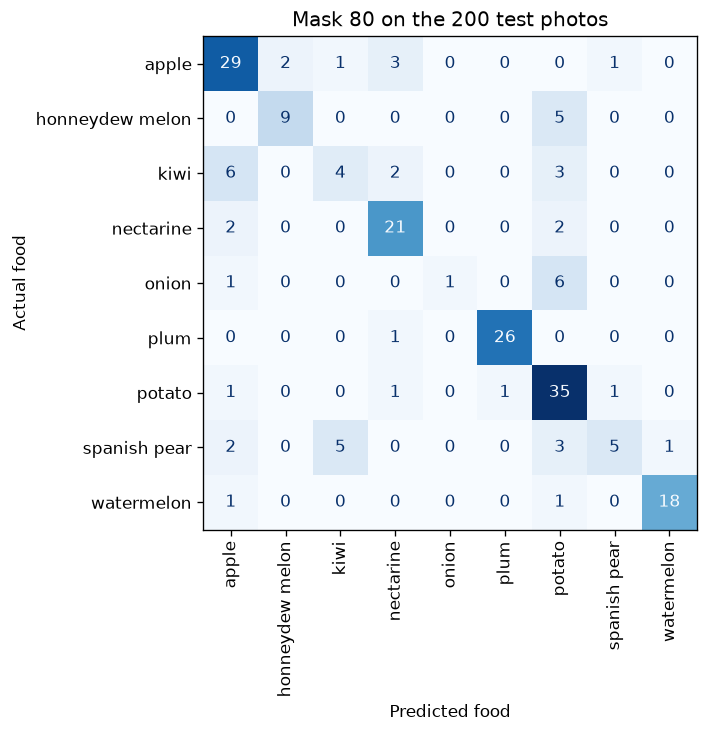

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

test_confusion = test_scores["confusion_matrix"]
test_display_names = [name.replace("_", " ") for name in test_class_names]

fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
ConfusionMatrixDisplay(test_confusion, display_labels=test_display_names).plot(
    ax=ax, cmap="Blues", colorbar=False, xticks_rotation=90
)
ax.set_title("Mask 80 on the 200 test photos")
ax.set_xlabel("Predicted food")
ax.set_ylabel("Actual food")
plt.show()
plt.close(fig)

**Final baseline.** Mask 80 correctly classified **148 of 200** test photos, with **74.0% accuracy** and **0.652 macro-F1**. The most frequent mistake was predicting apple for **6 of 15 kiwi photos**. The split keeps identified near-duplicates in training, but related photos may still appear across splits. Photos from a different setting would give a separate check of generalization.

## 7. What the Group Can Reuse

- **Baseline for comparison.** Compare Mask 80's **72.0% accuracy and 0.665 macro-F1** with other validation scores, and its **74.0% and 0.652** with other test scores. Sections 2–3 show how we built and selected it.
- **Shared evaluation.** Use `evaluate_predictions()` with the group's nine labels and one guess per photo in split-file order. [src/evaluate.py](../src/evaluate.py)
- **Shared image loader.** `load_image()` returns a resized RGB grid with values from 0 to 1 for models that work with image arrays. Section 2 shows the separate preparation used by the histogram baseline. [src/preprocess.py](../src/preprocess.py)
- **Shared split.** Use the same image paths, labels, and split assignments for every model. [data/dataset_split.csv](../data/dataset_split.csv)